# Deep learning for healthcare, session 2
# Does the neural network earn its place?

**Question for today:** on the same intensive care unit (ICU) patients, does a neural network predict 7-day in-hospital death better than the Cox model and random forest from notebook 03, by enough to justify being harder to understand?

A fair answer needs more than "which score is highest". We ask

1. How uncertain is the difference, with only about 40 deaths in the test set?
2. Are the risk numbers trustworthy (calibration)?
3. How many patients are flagged for clinical review, and how many patients who later die are missed?
4. Do the models flag the **same** patients?


## Setup

Locally: create and activate the Conda environment in `environment.yml` as described in the README. In Colab, uncomment the install line

In [1]:
# %pip install lifelines            # uncomment in Google Colab
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from IPython.display import display
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from lifelines import CoxPHFitter

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED); torch.set_num_threads(2)
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "font.size": 11})
NAVY, GREEN, LIME, GREY, RED, ORANGE = "#0b1f4b", "#00a37a", "#9ccf00", "#9aa3ad", "#d1495b", "#f28e2b"
COLORS = {"Cox": NAVY, "Logistic": "#4e79a7", "RandomForest": GREEN, "NeuralNet": ORANGE}

# 1. Rules of a fair comparison

| Rule | Why it matters here |
|---|---|
| Compare all four models on the same test patients and outcome: in-hospital death by day 7 after admission | Differences should reflect the models, rather than different patients or prediction tasks |
| Give every model the same patient details and measurements from the first 48 h | The network must earn its place using the same information. Measurements include summaries such as the lowest, highest and median heart rate |
| Calculate score differences on the same patients in each resample, with confidence intervals | With only 42 deaths in the test set, a small score advantage may reflect which patients were tested |
| Compare clinical review lists using the same risk threshold or the same number of patients to review | A model may find more patients who later die simply because it flags more patients overall |

> **Timing limit:** these are predictions after 48 h of data collection, but the outcome is death by day 7 from admission. The 20 deaths recorded with a stay of 2 days are not proof of deaths before hour 48: [PhysioNet excludes stays shorter than 48 h](https://physionet.org/content/challenge-2012/1.0.0/). Exact times would be needed to define the prediction point clearly

In [2]:
URL = "https://raw.githubusercontent.com/IE-ML-for-Healthcare/ICU_Survival_analysis/main/PhysionetChallenge2012-set-a.csv.gz"
local = [p for p in [Path("../ICU_Survival_analysis/PhysionetChallenge2012-set-a.csv.gz"),
                     Path("data/PhysionetChallenge2012-set-a.csv.gz")] if p.exists()]
raw = pd.read_csv(local[0] if local else URL, compression="gzip")
for col in ["SAPS-I", "SOFA"]:
    raw.loc[raw[col] < 0, col] = np.nan
raw = raw[raw["Length_of_stay"].ge(0)].reset_index(drop=True)

H = 7
dur = raw["Length_of_stay"].astype(float).to_numpy()
death = raw["In-hospital_death"].astype(int).to_numpy()
y = ((dur <= H) & (death == 1)).astype(int)
X = raw.drop(columns=["In-hospital_death", "Survival", "Length_of_stay", "recordid"])
FEATURES = X.columns.tolist()

idx = np.arange(len(X))
idx_trval, idx_test = train_test_split(idx, test_size=0.20, stratify=death, random_state=SEED)
idx_train, idx_val = train_test_split(idx_trval, test_size=0.25, stratify=death[idx_trval], random_state=SEED)
S = {"train": idx_train, "val": idx_val, "test": idx_test}
Y = {s: y[r] for s, r in S.items()}

imputer = SimpleImputer(strategy="median").fit(X.iloc[idx_train])
scaler = StandardScaler().fit(imputer.transform(X.iloc[idx_train]))
XI = {s: pd.DataFrame(imputer.transform(X.iloc[r]), columns=FEATURES) for s, r in S.items()}     # imputed, original units
XS = {s: scaler.transform(XI[s]).astype(np.float32) for s in S}                                   # imputed and scaled
print({s: f"{len(r)} patients, {Y[s].sum()} deaths by day {H}" for s, r in S.items()})

{'train': '2364 patients, 125 deaths by day 7', 'val': '788 patients, 41 deaths by day 7', 'test': '788 patients, 42 deaths by day 7'}


# 2. Four models and how we can inspect them

| Model | How it predicts | What we can inspect |
|---|---|---|
| **Cox models** from notebook 02 | Model the timing of death and discharge separately, then combine them into a 7-day risk | The coefficients and risk formula |
| **Logistic regression** | Add weighted inputs, then convert the total to a probability | One weight per input and a bias |
| **Random forest** with notebook 03 settings | Average predictions from 200 decision trees | Individual trees, although the full set is hard to summarise |
| **Neural network** with the session 1 structure | Combine inputs through two hidden layers | All weights and calculations, although the full prediction is hard to explain briefly |

We also check **calibration**: whether predicted risks match observed death rates. For the forest and network, we fit a risk adjustment called **Platt scaling** on validation patients. It uses a logistic regression to convert each model's score into an adjusted risk. We leave Cox and logistic regression predictions unchanged

In [3]:
# 2.1 Cox: competing risks of death and discharge, combined into a 7-day cumulative incidence (same as notebooks 02 and 03)
def predict_cif(cph_event, cph_comp, Xdf, t):
    H0e = cph_event.baseline_cumulative_hazard_.iloc[:, 0]; H0c = cph_comp.baseline_cumulative_hazard_.iloc[:, 0]
    tg = np.union1d(H0e.index.values.astype(float), H0c.index.values.astype(float))
    He0 = H0e.reindex(tg).ffill().fillna(0).to_numpy(); Hc0 = H0c.reindex(tg).ffill().fillna(0).to_numpy()
    pe = np.asarray(cph_event.predict_partial_hazard(Xdf)).ravel(); pc = np.asarray(cph_comp.predict_partial_hazard(Xdf)).ravel()
    He, Hc = np.outer(pe, He0), np.outer(pc, Hc0)
    dHe, dHc = np.outer(pe, np.diff(He0)), np.outer(pc, np.diff(Hc0))
    dH = dHe + dHc
    with np.errstate(invalid="ignore", divide="ignore"):
        share = np.where(dH > 0, dHe / dH, 0.0)
    inc = np.exp(-(He[:, :-1] + Hc[:, :-1])) * (1 - np.exp(-dH)) * share
    F = np.zeros((len(Xdf), tg.size)); F[:, 1:] = np.cumsum(inc, axis=1)
    j = int(np.clip(np.searchsorted(tg, float(t), side="right") - 1, 0, tg.size - 1))
    return F[:, j]

df_tr = XI["train"].assign(duration=dur[idx_train], event=death[idx_train])
cox_death = CoxPHFitter(penalizer=0.1).fit(df_tr, "duration", "event")
cox_disc = CoxPHFitter(penalizer=0.1).fit(df_tr.assign(event=1 - df_tr["event"]), "duration", "event")
P = {m: {} for m in COLORS}
for s in S:
    P["Cox"][s] = predict_cif(cox_death, cox_disc, XI[s], H)

# 2.2 Logistic regression with the penalty strength chosen by 5-fold cross-validation on training patients
CV = StratifiedKFold(5, shuffle=True, random_state=SEED)
# Imputation and scaling sit inside the pipeline, so each cross-validation fold learns them from its own training part
XR = {s: X.iloc[r].reset_index(drop=True) for s, r in S.items()}
logreg = GridSearchCV(Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler()),
                                ("model", LogisticRegression(max_iter=5000))]),
                      {"model__C": np.logspace(-4, 4, 10)}, scoring="neg_log_loss", cv=CV).fit(XR["train"], Y["train"])
for s in S:
    P["Logistic"][s] = logreg.predict_proba(XR[s])[:, 1]

# 2.3 Random forest: notebook 03 grid, tuned by 5-fold cross-validation, then Platt scaling on validation
rf = GridSearchCV(Pipeline([("impute", SimpleImputer(strategy="median")),
                            ("model", RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1))]),
                  {"model__max_depth": [4, 6, 8], "model__min_samples_leaf": [25, 50]}, scoring="roc_auc", cv=CV, n_jobs=-1).fit(XR["train"], Y["train"])
def logit(p): p = np.clip(p, 1e-6, 1 - 1e-6); return np.log(p / (1 - p)).reshape(-1, 1)
RAW = {"RandomForest": {s: rf.predict_proba(XR[s])[:, 1] for s in S}}
print("Random forest settings:", rf.best_params_)

Random forest settings: {'model__max_depth': 8, 'model__min_samples_leaf': 25}


In [4]:
# 2.4 Neural network: session 1 design, trained 5 times with different seeds and averaged (an "ensemble")
def make_mlp(n_in, seed):
    torch.manual_seed(seed)
    return nn.Sequential(nn.Linear(n_in, 32), nn.ReLU(), nn.Dropout(0.2), nn.Linear(32, 16), nn.ReLU(), nn.Dropout(0.2), nn.Linear(16, 1))

def train_net(model, Xa, ya, Xv, yv, seed, epochs=1500, lr=0.003, wd=1e-3, patience=100, pos_weight=None):
    torch.manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    lossf = nn.BCEWithLogitsLoss(pos_weight=None if pos_weight is None else torch.tensor(float(pos_weight)))
    Xa_t, ya_t, Xv_t, yv_t = torch.tensor(Xa), torch.tensor(ya, dtype=torch.float32), torch.tensor(Xv), torch.tensor(yv, dtype=torch.float32)
    best, state, wait = np.inf, None, 0
    for ep in range(epochs):
        model.train(); opt.zero_grad(); lossf(model(Xa_t).squeeze(1), ya_t).backward(); opt.step()
        model.eval()
        with torch.no_grad(): vl = lossf(model(Xv_t).squeeze(1), yv_t).item()
        if vl < best - 1e-5: best, state, wait = vl, {k: v.clone() for k, v in model.state_dict().items()}, 0
        else:
            wait += 1
            if wait >= patience: break
    model.load_state_dict(state); model.eval(); return model

def predict(model, Xa):
    with torch.no_grad(): return torch.sigmoid(model(torch.tensor(Xa))).numpy().ravel()

SEEDS = range(5)
nets = [train_net(make_mlp(XS["train"].shape[1], s), XS["train"], Y["train"], XS["val"], Y["val"], s) for s in SEEDS]
RAW["NeuralNet"] = {s: np.mean([predict(m, XS[s]) for m in nets], axis=0) for s in S}
single_seed_auc = [roc_auc_score(Y["test"], predict(m, XS["test"])) for m in nets]

# Platt scaling for forest and network, fitted on validation patients only
for m in ["RandomForest", "NeuralNet"]:
    cal = LogisticRegression(C=1e6).fit(logit(RAW[m]["val"]), Y["val"])
    for s in S:
        P[m][s] = cal.predict_proba(logit(RAW[m][s]))[:, 1]
print("Single-network test AUROC by seed:", np.round(single_seed_auc, 3))

Single-network test AUROC by seed: [0.843 0.852 0.849 0.841 0.847]


Why average five networks? Session 1 showed that different random starting points can lead to different alerts. Averaging predictions from five trained networks can make results more stable. This set of models is called an **ensemble**. It requires storing and running five networks instead of one

# 3. Ranking, uncertainty and calibration

We calculate three scores on the 788 test patients

- **Area under the receiver operating characteristic curve (AUROC):** how well the model ranks patients who die by day 7 above those who do not. A score of 0.5 means chance-level ranking; 1.0 means perfect ranking
- **Area under the precision-recall curve (AUPRC):** summarises the balance between finding deaths and avoiding false alerts as the threshold changes. The code uses **average precision**, a common summary of this curve. Its no-skill reference is the death rate, about 0.05
- **Brier score:** the average squared difference between each predicted probability and the actual outcome, coded 0 or 1. Lower is better; it reflects more than calibration alone

**How we estimate uncertainty:** draw 2,000 new samples from the test patients, allowing a patient to appear more than once. For each sample, compare every model with Cox using exactly the same patients. This is a **paired bootstrap**. The middle 95% of the score differences gives an approximate **95% confidence interval**

If the interval includes zero, this comparison does not establish which model performs better. It also does not prove that the models are equivalent

,AUROC,AUPRC,Brier,mean predicted risk
Cox,0.864,0.267,0.046,0.047
Logistic,0.880,0.281,0.046,0.046
RandomForest,0.863,0.324,0.043,0.046
NeuralNet,0.852,0.238,0.045,0.049
Observed death rate,NaN,NaN,NaN,0.053


,model,metric,gap_vs_Cox,ci_low,ci_high
0,Logistic,AUROC,0.016,-0.012,0.047
1,Logistic,AUPRC,0.014,-0.049,0.079
2,RandomForest,AUROC,-0.001,-0.049,0.051
3,RandomForest,AUPRC,0.057,-0.044,0.162
4,NeuralNet,AUROC,-0.011,-0.048,0.026
5,NeuralNet,AUPRC,-0.029,-0.125,0.043


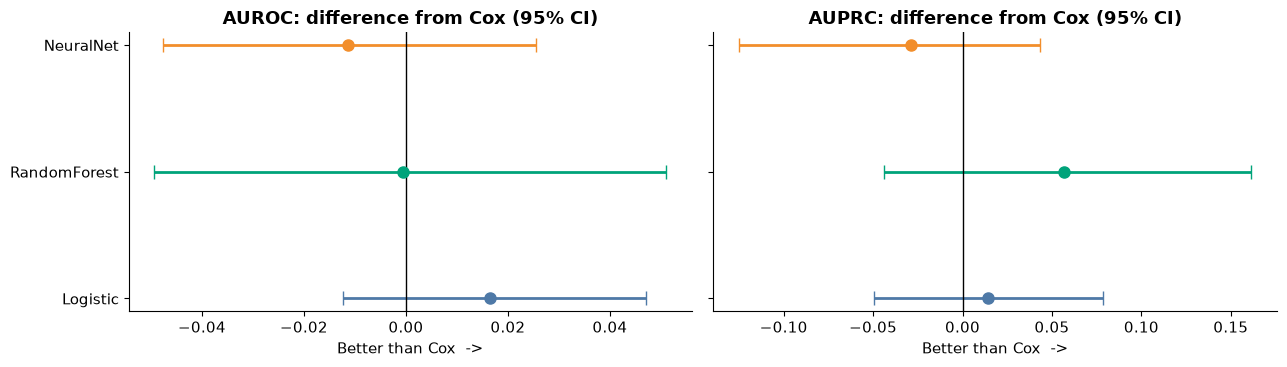

In [5]:
yt = Y["test"]
MODELS = list(COLORS)
tbl = pd.DataFrame({m: {"AUROC": roc_auc_score(yt, P[m]["test"]), "AUPRC": average_precision_score(yt, P[m]["test"]),
                        "Brier": brier_score_loss(yt, P[m]["test"]), "mean predicted risk": P[m]["test"].mean()}
                    for m in MODELS}).T
tbl.loc["Observed death rate", "mean predicted risk"] = yt.mean()
display(tbl.round(3))

rng = np.random.default_rng(SEED)
B = [rng.integers(0, len(yt), len(yt)) for _ in range(2000)]
B = [b for b in B if yt[b].min() != yt[b].max()]
gap_rows = []
for m in MODELS[1:]:
    for metric, f in [("AUROC", roc_auc_score), ("AUPRC", average_precision_score)]:
        g = np.array([f(yt[b], P[m]["test"][b]) - f(yt[b], P["Cox"]["test"][b]) for b in B])
        gap_rows.append({"model": m, "metric": metric, "gap_vs_Cox": f(yt, P[m]["test"]) - f(yt, P["Cox"]["test"]),
                         "ci_low": np.percentile(g, 2.5), "ci_high": np.percentile(g, 97.5)})
gaps = pd.DataFrame(gap_rows)
display(gaps.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, metric in zip(axes, ["AUROC", "AUPRC"]):
    d = gaps[gaps.metric == metric].reset_index(drop=True)
    for k, r in d.iterrows():
        ax.errorbar(r.gap_vs_Cox, k, xerr=[[r.gap_vs_Cox - r.ci_low], [r.ci_high - r.gap_vs_Cox]], fmt="o",
                    color=COLORS[r.model], capsize=5, ms=8, lw=2)
    ax.axvline(0, color="black", lw=1); ax.set_yticks(range(len(d))); ax.set_yticklabels(d.model)
    ax.set_title(f"{metric}: difference from Cox (95% CI)"); ax.set_xlabel("Better than Cox  ->")
plt.tight_layout(); plt.show()

**What this shows** (tables above)

- Test AUROC ranges from 0.852 for the network to 0.880 for logistic regression. Cox scores 0.864 and the forest 0.863
- Every confidence interval for a difference from Cox includes zero. For the network, the AUROC difference is -0.011, with an interval from -0.048 to +0.026
- With only 42 test deaths, these comparisons do not establish an improvement over Cox. We did not compare every pair of models
- The network has the lowest observed score on both ranking measures in this run

> **How to report this:** Cox scored higher than the network on this test set, but the comparison is too uncertain to establish which performs better in the wider patient population

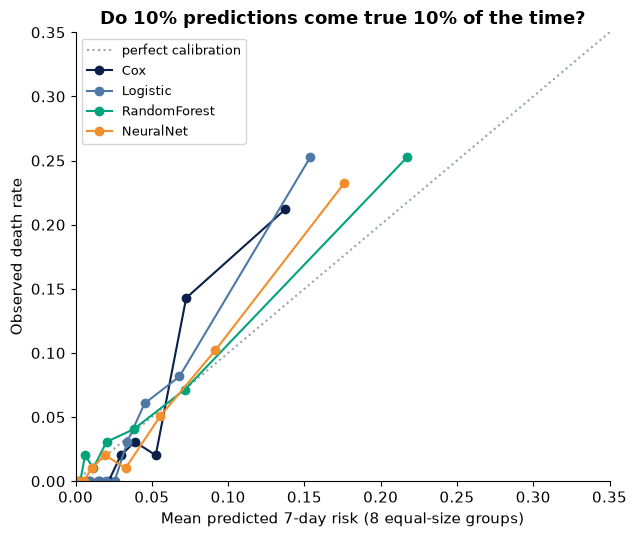

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.plot([0, 0.35], [0, 0.35], ":", color=GREY, label="perfect calibration")
for m in MODELS:
    fp, mp = calibration_curve(yt, P[m]["test"], n_bins=8, strategy="quantile")
    ax.plot(mp, fp, "o-", color=COLORS[m], label=m)
ax.set_xlim(0, 0.35); ax.set_ylim(0, 0.35)
ax.set_xlabel("Mean predicted 7-day risk (8 equal-size groups)"); ax.set_ylabel("Observed death rate")
ax.set_title("Do 10% predictions come true 10% of the time?"); ax.legend(fontsize=9); plt.tight_layout(); plt.show()

**What this shows**

- The curves are near the diagonal at low predicted risks, where most patients fall. The diagonal means predicted and observed risks match
- In their highest predicted-risk groups, Cox and logistic regression predict about 14% to 16% risk, while about 21% to 25% of patients died. They underestimate risk in those groups
- The adjusted forest and network predictions are closer to the diagonal in their highest-risk groups. This plot alone does not show how much of that difference comes from Platt scaling
- Each point represents about 99 patients. The highest-risk groups contain only about 20 deaths, so small differences are uncertain

# 4. Optional: do rare outcomes always need class weighting?

**Claim to test:** "Deaths are rare, so we must give them more weight during training."

We compare two individual networks with the same random starting point. One uses ordinary training; the other gives each death about 18 times more weight in the training penalty (`pos_weight`), based on the training set's non-death-to-death ratio. We then apply Platt scaling, fitted on validation patients, to adjust the weighted model's risk estimates.

**Look for:** does weighting help identify deaths when we review the same 79 patients, or mainly increase the scores and alerts?

This is a demonstration of a possible pitfall, not a required training step.

,ordinary loss,"weighted (deaths x18), raw","weighted, after Platt scaling"
AUROC,0.843,0.853,0.853
mean predicted risk,0.045,0.392,0.050
alerts per 100 at 10% threshold,15.609,93.528,11.294
deaths flagged at 10% (of 42),28.000,42.000,21.000
deaths in top 79,18.000,20.000,20.000
observed death rate,0.053,0.053,0.053


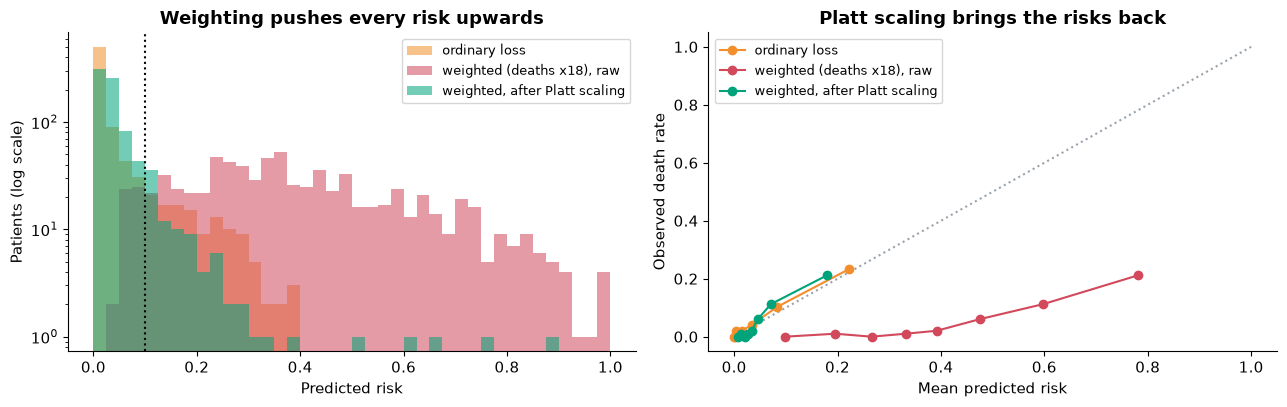

In [7]:
# Same seed, ordinary vs weighted loss; then undo the weighting with Platt scaling fitted on validation patients
pw = (Y["train"] == 0).sum() / (Y["train"] == 1).sum()
net_w = train_net(make_mlp(XS["train"].shape[1], 0), XS["train"], Y["train"], XS["val"], Y["val"], 0, pos_weight=pw)
raw_w = {s: predict(net_w, XS[s]) for s in ["val", "test"]}
cal_w = LogisticRegression(C=1e6).fit(logit(raw_w["val"]), Y["val"])

versions = {"ordinary loss": predict(nets[0], XS["test"]),
            f"weighted (deaths x{pw:.0f}), raw": raw_w["test"],
            "weighted, after Platt scaling": cal_w.predict_proba(logit(raw_w["test"]))[:, 1]}
cap = int(round(0.10 * len(yt)))
def summarise(p):
    f = p >= 0.10
    return [roc_auc_score(yt, p), p.mean(), 100 * f.mean(), int((f & (yt == 1)).sum()), int(yt[np.argsort(-p)[:cap]].sum())]
cmp = pd.DataFrame({k: summarise(p) for k, p in versions.items()},
                   index=["AUROC", "mean predicted risk", "alerts per 100 at 10% threshold",
                          f"deaths flagged at 10% (of {yt.sum()})", f"deaths in top {cap}"])
cmp.loc["observed death rate"] = [yt.mean()] * 3
display(cmp.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
bins = np.linspace(0, 1, 41)
hist_colors = [ORANGE, RED, GREEN]
for (lab, p), c in zip(versions.items(), hist_colors):
    axes[0].hist(p, bins=bins, color=c, alpha=0.55, label=lab)
axes[0].axvline(0.1, color="black", ls=":"); axes[0].set_yscale("log")
axes[0].set_xlabel("Predicted risk"); axes[0].set_ylabel("Patients (log scale)"); axes[0].legend(fontsize=9)
axes[0].set_title("Weighting pushes every risk upwards")
axes[1].plot([0, 1], [0, 1], ":", color=GREY)
for (lab, p), c in zip(versions.items(), hist_colors):
    fp, mp = calibration_curve(yt, p, n_bins=8, strategy="quantile"); axes[1].plot(mp, fp, "o-", color=c, label=lab)
axes[1].set_xlabel("Mean predicted risk"); axes[1].set_ylabel("Observed death rate"); axes[1].legend(fontsize=9)
axes[1].set_title("Platt scaling brings the risks back"); plt.tight_layout(); plt.show()

**What did we learn?**

- **More alerts can look like better detection:** the raw weighted model flags all 42 deaths, but also flags about 94 of every 100 patients
- **At the same workload, the gain is uncertain:** among the top 79 patients, the ordinary model finds 18 deaths and the weighted model finds 20. This single comparison does not establish a reliable improvement
- **Calibration changes the risk scale:** Platt scaling reduces the weighted model's average estimate from 39.2% to 5.0%, near the observed 5.3%. It leaves the top-79 list unchanged in this run. Matching the average alone does not establish accurate risks across patient groups

> **Takeaway:** Use class weighting only when validation shows it helps; finding more deaths means little if you flag almost everyone

Class weighting is optional. To change how many patients receive an alert, choose the threshold on validation data, as discussed in section 5. See [PyTorch on positive-class weighting](https://docs.pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html) and [scikit-learn on threshold tuning](https://scikit-learn.org/stable/modules/classification_threshold.html)


# 5. From scores to decisions: two ways to compare

A ranking score does not tell a clinical team how many patients it will need to review. We compare two rules

| Rule | Question it answers |
|---|---|
| **Same risk threshold: 10%** | If we review everyone with predicted risk of at least 10%, how many alerts do we get, and how many patients who later die are flagged? |
| **Same review capacity: top 10%** | If we can review only 79 of 788 patients, which model places the most patients who later die on that list? |

**Net benefit** combines true alerts and false alerts into one score. At a 10% threshold, it subtracts one ninth of a true alert for each false alert, then divides by the number of patients. This represents a chosen trade-off, not a measured effect on health

Here, a **true alert** means flagging a patient who died by day 7. It does not mean the alert would have prevented that death

,alerts_per_100 @10%,deaths_caught @10%,net_benefit @10%,deaths_in_top_79
model,,,,
Cox,9.3909,18,0.0149,18
Logistic,8.5025,20,0.0188,21
RandomForest,11.6751,25,0.0223,23
NeuralNet,16.4975,28,0.0212,17


,net benefit gap vs Cox,ci_low,ci_high
Logistic,0.0038,-0.0044,0.0125
RandomForest,0.0073,-0.0031,0.0180
NeuralNet,0.0062,-0.0030,0.0161


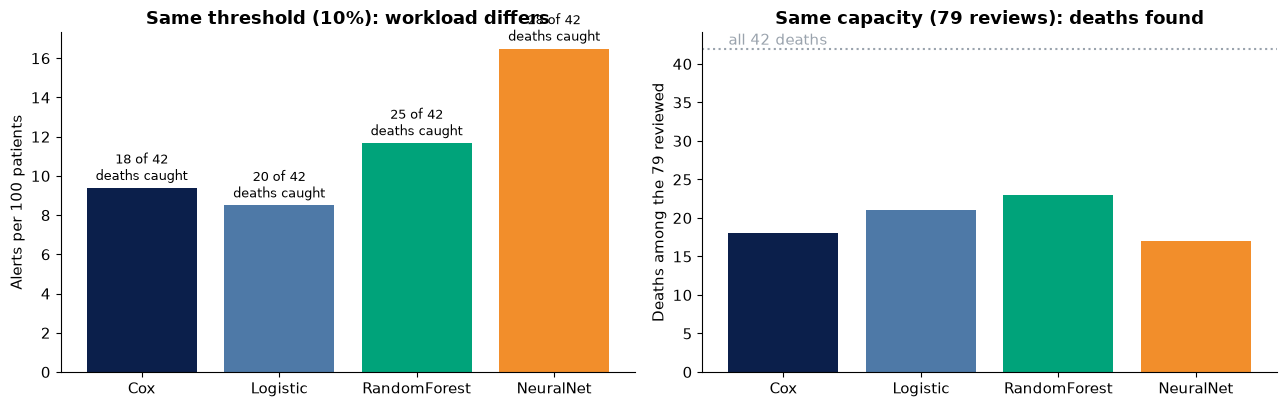

In [8]:
T = 0.10
CAP = int(round(0.10 * len(yt)))
def net_benefit(y_, p_, t):
    f = p_ >= t; return (f & (y_ == 1)).sum() / len(y_) - (f & (y_ == 0)).sum() / len(y_) * t / (1 - t)

rows = []
for m in MODELS:
    p = P[m]["test"]; f = p >= T
    top = np.argsort(-p)[:CAP]
    rows.append({"model": m, "alerts_per_100 @10%": 100 * f.mean(), "deaths_caught @10%": int((f & (yt == 1)).sum()),
                 "net_benefit @10%": net_benefit(yt, p, T), f"deaths_in_top_{CAP}": int(yt[top].sum())})
ops = pd.DataFrame(rows).set_index("model")
display(ops.round(4))

nb_ci = {}
for m in MODELS[1:]:
    g = np.array([net_benefit(yt[b], P[m]["test"][b], T) - net_benefit(yt[b], P["Cox"]["test"][b], T) for b in B])
    nb_ci[m] = (net_benefit(yt, P[m]["test"], T) - net_benefit(yt, P["Cox"]["test"], T), np.percentile(g, 2.5), np.percentile(g, 97.5))
display(pd.DataFrame(nb_ci, index=["net benefit gap vs Cox", "ci_low", "ci_high"]).T.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
x = np.arange(len(MODELS))
axes[0].bar(x, ops["alerts_per_100 @10%"], color=[COLORS[m] for m in MODELS])
for k, m in enumerate(MODELS):
    axes[0].text(k, ops.loc[m, "alerts_per_100 @10%"] + 0.4, f"{ops.loc[m, 'deaths_caught @10%']} of {yt.sum()}\ndeaths caught", ha="center", fontsize=9)
axes[0].set_xticks(x); axes[0].set_xticklabels(MODELS); axes[0].set_ylabel("Alerts per 100 patients")
axes[0].set_title("Same threshold (10%): workload differs")
axes[1].bar(x, ops[f"deaths_in_top_{CAP}"], color=[COLORS[m] for m in MODELS])
axes[1].axhline(yt.sum(), color=GREY, ls=":"); axes[1].text(-0.4, yt.sum() + 0.5, f"all {yt.sum()} deaths", color=GREY)
axes[1].set_xticks(x); axes[1].set_xticklabels(MODELS); axes[1].set_ylabel(f"Deaths among the {CAP} reviewed")
axes[1].set_title(f"Same capacity ({CAP} reviews): deaths found"); plt.tight_layout(); plt.show()

**What this shows** (tables above)

- **Same threshold:** at 10% risk, the network raises 16.4 alerts per 100 patients and flags 27 of 42 patients who died. Cox raises 9.4 alerts and flags 18. The network identifies more of these patients, with more reviews required
- **Same capacity:** among 79 reviews, the forest flags 23 patients who died, logistic regression 21, Cox 18 and the network 17
- **Net benefit:** each model scores slightly higher than Cox at the chosen trade-off, but every confidence interval for the difference includes zero

The network flags the most patients who died under the first rule and the fewest under the second. A model comparison needs to state how the predictions will be used

## 5.1 Do the models flag the same patients?

Even with similar totals, two models can put **different people** on the review list. That matters for the patient, and for any audit of who benefits

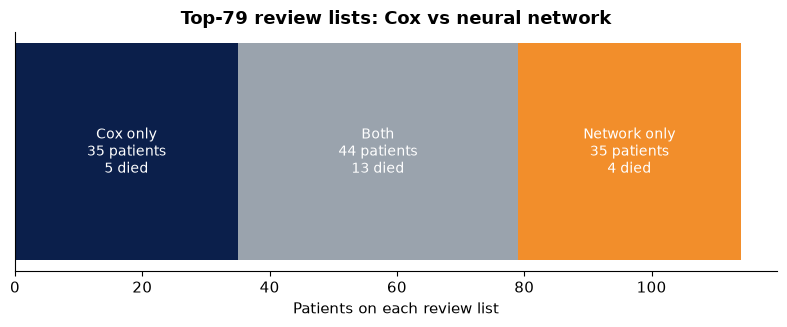

Share of patients the two lists have in common (Jaccard index, 1 = identical lists):


,Cox,Logistic,RandomForest,NeuralNet
Cox,1.00,0.39,0.32,0.39
Logistic,0.39,1.00,0.52,0.49
RandomForest,0.32,0.52,1.00,0.39
NeuralNet,0.39,0.49,0.39,1.00


In [9]:
tops = {m: set(np.argsort(-P[m]["test"])[:CAP]) for m in MODELS}
deaths = set(np.where(yt == 1)[0])
both = tops["Cox"] & tops["NeuralNet"]
only_cox, only_nn = tops["Cox"] - tops["NeuralNet"], tops["NeuralNet"] - tops["Cox"]
fig, ax = plt.subplots(figsize=(8, 3.4))
parts = [("Cox only", len(only_cox), len(only_cox & deaths), NAVY), ("Both", len(both), len(both & deaths), GREY),
         ("Network only", len(only_nn), len(only_nn & deaths), ORANGE)]
left = 0
for name, n_, d_, c in parts:
    ax.barh(0, n_, left=left, color=c); ax.text(left + n_ / 2, 0, f"{name}\n{n_} patients\n{d_} died", ha="center", va="center", color="white", fontsize=10)
    left += n_
ax.set_yticks([]); ax.set_xlabel("Patients on each review list"); ax.set_title(f"Top-{CAP} review lists: Cox vs neural network")
plt.tight_layout(); plt.show()
jac = pd.DataFrame({a: {b: len(tops[a] & tops[b]) / len(tops[a] | tops[b]) for b in MODELS} for a in MODELS})
print("Share of patients the two lists have in common (Jaccard index, 1 = identical lists):"); display(jac.round(2))

**What this shows**

- Cox and the network each select 79 patients, but only 44 appear on both lists. Each model selects 35 people the other does not
- Among those 70 patients selected by only one model, 9 died: 5 selected only by Cox and 4 only by the network
- The **Jaccard index** counts patients on both lists and divides by everyone on either list. It ranges from about 0.30 to 0.50 across model pairs. This differs from the share of one 79-patient list that is shared

> **What should the team do?** Before switching models, review which patients gain or lose alerts and whether the differences make clinical sense. Define who receives each alert and what assessment it triggers. An alert prompts review, not automatic treatment; no alert does not mean no care. Reviewing both lists would require 114 reviews instead of 79, so check capacity before combining them. These results do not show that either model prevents deaths

# 6. A 2026 challenger: a tabular foundation model

Sections 2 to 5 used a network trained **from scratch** on 2,364 patients. Since 2023 a different kind of deep learning model has appeared for tables: the **tabular foundation model**. The best known is **TabPFN** ([Hollmann et al., 2025, Nature](https://doi.org/10.1038/s41586-024-08328-6))

| Ordinary model | Tabular foundation model |
|---|---|
| Learns weights from **our** training patients | Already trained, by its makers, on millions of **synthetic** (computer-generated) tables |
| Training step, then prediction | No training on our data: it reads our training patients as **context**, like examples in a prompt, and predicts the test patients in one pass |
| Needs filled gaps and scaling | Handles missing values and scaling itself |

Prior Labs reports that recent versions beat tuned tree models on small and medium datasets ([TabPFN-2.5 report](https://arxiv.org/abs/2511.08667)). Our cohort is exactly that size, so this is the strongest current test of "does deep learning earn its place on tables?"

## 6.1 Which version, and why TabPFN-2

| Version | Licence of the model weights | Login needed to download | Use in a hospital product | Choice for this class |
|---|---|---|---|---|
| **TabPFN-2** (2025) | Prior Labs License: Apache 2.0 plus an attribution requirement | **No** | Allowed, with attribution | **Used here** |
| TabPFN-2.5, 2.6, 3, 3.5 (default in the current package) | Non-commercial | Yes: create a Prior Labs account and accept the terms | Needs a paid enterprise licence | Mention only |

Why TabPFN-2
- **Free for every student, with no account:** it downloads on first use, so nobody has to accept terms or manage a login token
- **The licence fits healthcare deployment:** a hospital or company can use it in a product, with attribution. Newer versions are stronger on benchmarks but are free only for non-commercial work; using them in care needs a commercial contract
- **The most peer-reviewed evidence:** the Nature paper describes TabPFN-2. Clinical studies have since used both TabPFN-2 and TabPFN-2.5, for example for ICU mortality in cancer patients ([Liu et al., 2026, JAMIA Open](https://academic.oup.com/jamiaopen/article/9/4/ooag148/8748331))
- **The trade-off:** it is an older, weaker version, and its makers set a 1,000-row limit on laptop processors. We lift that limit for our 2,364 patients, which works but is slower

There is no "official" healthcare version. What a hospital should care about is the same for any version: licence for clinical use, whether data stay on its own computers, and evidence on its own patients

Sources for licences and access: [TabPFN README](https://github.com/PriorLabs/TabPFN), [Prior Labs: gated models](https://docs.priorlabs.ai/how-to-access-gated-models.md)

In [10]:
# %pip install tabpfn        # uncomment in Google Colab, or see environment.yml
# 6.2 TabPFN-2 on our patients: no training, the training patients are the context
# Runs locally on the laptop processor; no patient data leave this computer. First run downloads the weights (internet needed)
import os, time
os.environ.setdefault("TABPFN_ALLOW_CPU_LARGE_DATASET", "1")      # 2,364 context rows is above the default laptop limit of 1,000
TABPFN_OK = False
try:
    from tabpfn import TabPFNClassifier
    from tabpfn.constants import ModelVersion
    tab = TabPFNClassifier.create_default_for_version(ModelVersion.V2, n_estimators=4, device="cpu",
                                                      ignore_pretraining_limits=True, random_state=SEED)
    t0 = time.time(); tab.fit(XR["train"], Y["train"]); t_fit = time.time() - t0          # raw inputs: gaps and units left as they are
    t0 = time.time(); RAW["TabPFN"] = {s: tab.predict_proba(XR[s])[:, 1] for s in ["val", "test"]}; t_pred = time.time() - t0
    TABPFN_OK = True
    print(f"'fit' took {t_fit:.0f} s (stores the context); predicting {len(XR['val']) + len(XR['test'])} patients took {t_pred:.0f} s")
except Exception as e:
    print(f"TabPFN did not run: {type(e).__name__}: {str(e)[:300]}")
    print("Check: `pip install tabpfn`, and internet access to huggingface.co or storage.googleapis.com for the first download")

'fit' took 3 s (stores the context); predicting 1576 patients took 1598 s


,AUROC,AUPRC,Brier,alerts_per_100 @10%,deaths_caught @10%,net_benefit @10%,deaths_in_top_79,shared top list with Cox
Cox,0.864,0.267,0.046,9.391,18,0.015,18,NaN
Logistic,0.880,0.281,0.046,8.503,20,0.019,21,NaN
RandomForest,0.863,0.324,0.043,11.675,25,0.022,23,NaN
NeuralNet,0.852,0.238,0.045,16.497,28,0.021,17,NaN
TabPFN,0.892,0.381,0.041,12.056,26,0.023,24,0.386


,gap vs Cox,ci_low,ci_high
AUROC,0.0286,-0.0142,0.0739
AUPRC,0.1139,-0.0027,0.2233
net benefit @10%,0.0083,-0.0014,0.0183


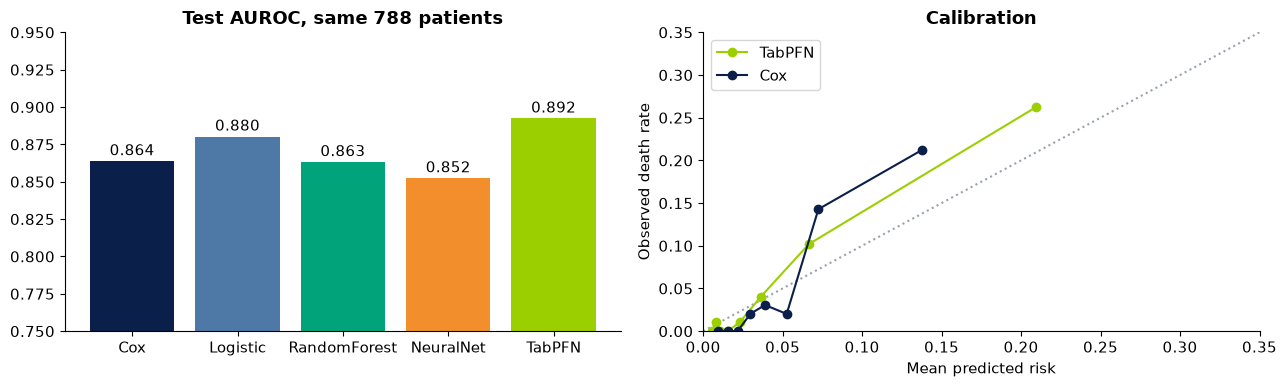

Reading the result: TabPFN AUROC 0.892, gap vs Cox +0.029 (95% CI -0.014 to +0.074), so it is not shown to differ from Cox: the interval includes zero. With 79 reviews it finds 24 of 42 deaths (Cox 18); its review list shares 39% of patients with Cox's list (Jaccard index).


In [11]:
# 6.3 Same rules as everyone else: Platt scaling on validation, then the same test patients, bootstrap and operating points
def report_challenger(name, raw):
    cal = LogisticRegression(C=1e6).fit(logit(raw["val"]), Y["val"])
    p_new = cal.predict_proba(logit(raw["test"]))[:, 1]
    p_cox = P["Cox"]["test"]
    gaps_new = {}
    for metric, f in [("AUROC", roc_auc_score), ("AUPRC", average_precision_score)]:
        g = np.array([f(yt[b], p_new[b]) - f(yt[b], p_cox[b]) for b in B])
        gaps_new[metric] = (f(yt, p_new) - f(yt, p_cox), np.percentile(g, 2.5), np.percentile(g, 97.5))
    g_nb = np.array([net_benefit(yt[b], p_new[b], T) - net_benefit(yt[b], p_cox[b], T) for b in B])
    top_new = set(np.argsort(-p_new)[:CAP])
    row = {"AUROC": roc_auc_score(yt, p_new), "AUPRC": average_precision_score(yt, p_new), "Brier": brier_score_loss(yt, p_new),
           "alerts_per_100 @10%": 100 * (p_new >= T).mean(), "deaths_caught @10%": int(((p_new >= T) & (yt == 1)).sum()),
           "net_benefit @10%": net_benefit(yt, p_new, T), f"deaths_in_top_{CAP}": int(yt[list(top_new)].sum()),
           "shared top list with Cox": len(top_new & tops["Cox"]) / len(top_new | tops["Cox"])}
    table_ = pd.concat([tbl[["AUROC", "AUPRC", "Brier"]].drop(index="Observed death rate").join(ops), pd.DataFrame(row, index=[name])])
    display(table_.round(3))
    gaps_tbl = pd.DataFrame(gaps_new, index=["gap vs Cox", "ci_low", "ci_high"]).T
    gaps_tbl.loc["net benefit @10%"] = [net_benefit(yt, p_new, T) - net_benefit(yt, p_cox, T), np.percentile(g_nb, 2.5), np.percentile(g_nb, 97.5)]
    display(gaps_tbl.round(4))

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    allm = MODELS + [name]; cols = [COLORS[m] for m in MODELS] + [LIME]
    aucs = [roc_auc_score(yt, P[m]["test"]) for m in MODELS] + [row["AUROC"]]
    axes[0].bar(allm, aucs, color=cols); axes[0].set_ylim(0.75, 0.95)
    for k, v in enumerate(aucs): axes[0].text(k, v + 0.004, f"{v:.3f}", ha="center")
    axes[0].set_title("Test AUROC, same 788 patients")
    fp, mp = calibration_curve(yt, p_new, n_bins=8, strategy="quantile")
    axes[1].plot([0, 0.35], [0, 0.35], ":", color=GREY); axes[1].plot(mp, fp, "o-", color=LIME, label=name)
    fp, mp = calibration_curve(yt, p_cox, n_bins=8, strategy="quantile"); axes[1].plot(mp, fp, "o-", color=NAVY, label="Cox")
    axes[1].set_xlim(0, 0.35); axes[1].set_ylim(0, 0.35); axes[1].legend()
    axes[1].set_xlabel("Mean predicted risk"); axes[1].set_ylabel("Observed death rate"); axes[1].set_title("Calibration")
    plt.tight_layout(); plt.show()

    lo, hi = gaps_new["AUROC"][1], gaps_new["AUROC"][2]
    verdict = ("better than Cox: the whole interval is above zero" if lo > 0 else
               "worse than Cox: the whole interval is below zero" if hi < 0 else
               "not shown to differ from Cox: the interval includes zero")
    print(f"Reading the result: {name} AUROC {row['AUROC']:.3f}, gap vs Cox {gaps_new['AUROC'][0]:+.3f} "
          f"(95% CI {lo:+.3f} to {hi:+.3f}), so it is {verdict}. "
          f"With {CAP} reviews it finds {row[f'deaths_in_top_{CAP}']} of {yt.sum()} deaths (Cox {ops.loc['Cox', f'deaths_in_top_{CAP}']}); "
          f"its review list shares {row['shared top list with Cox']:.0%} of patients with Cox's list (Jaccard index).")
    return p_new

if TABPFN_OK:
    P["TabPFN"] = {"test": report_challenger("TabPFN", RAW["TabPFN"])}
else:
    print("Skipped: TabPFN did not run in 6.2. Every other result in this notebook is unaffected")

**How to read this section**
- The code prints its own reading of the result, using the same rule as section 3: a gap counts only if its 95% interval excludes zero
- Compare three things: the AUROC gap and its interval, deaths found with 79 reviews, and how many patients its review list shares with Cox's
- Note the timing line: "fit" is almost instant because nothing is learned; the work happens at prediction time. That is the opposite of every other model in this course

## 6.4 Responsible AI: what changes with a foundation model

| Question | Trained-from-scratch network | Tabular foundation model |
|---|---|---|
| What does it use? | Patterns in our 2,364 patients | Our patients **plus** assumptions its makers built into millions of synthetic tables, which no clinician can inspect |
| What exactly is "the model"? | Fixed weights after training | Weights **plus** the context rows: change, add or remove training patients and predictions change without any retraining. Version the context data like the model |
| Can we explain it faithfully? | Hard | Harder: explanation tools exist ([TabPFN extensions](https://github.com/PriorLabs/tabpfn-extensions)), but the same faithfulness checks from session 4 apply |
| Where does the data go? | Stays on our computers | Stays local here. The makers' hosted option (TabPFN client) sends rows to their servers, which needs a data protection review before any patient data are used |
| Who is accountable? | The hospital and its supplier | Adds a third party: the foundation model maker, its licence terms and its update schedule |

> **Implication:** "state of the art on benchmarks" is not evidence for **our** patients. A foundation model must pass the same tests as everyone else: same patients, intervals, calibration, workload and who gets flagged

# 7. What 48-hour summaries hide

Every model above sees **summaries**: first, last, lowest, highest and median values. Two measurement traces can have identical summaries but change at different times. The example below is **synthetic**, built only to make the point

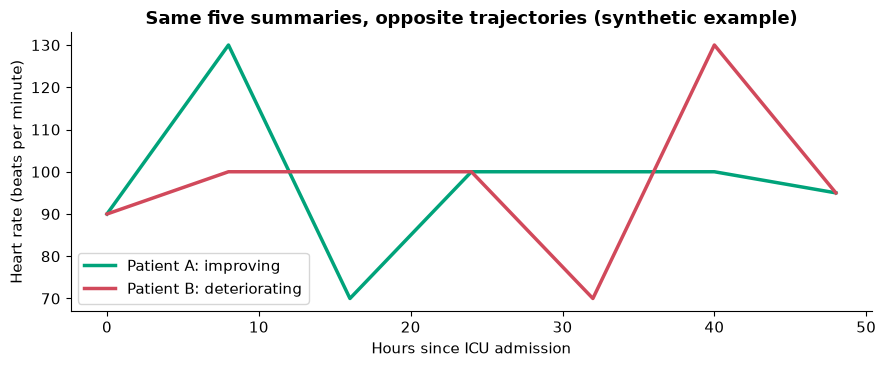

,first,last,lowest,highest,median
Patient A,90.0,95.0,70.0,130.0,100.0
Patient B,90.0,95.0,70.0,130.0,100.0


In [12]:
# Synthetic illustration (not patient data): two heart-rate series with the same first, last, lowest, highest and median values
t = np.arange(0, 49, 1.0)
a = np.interp(t, [0, 8, 16, 24, 40, 48], [90, 130, 70, 100, 100, 95])     # unstable early, then steady
b = np.interp(t, [0, 8, 24, 32, 40, 48], [90, 100, 100, 70, 130, 95])     # steady early, unstable late
def summ(s): return {"first": s[0], "last": s[-1], "lowest": s.min(), "highest": s.max(), "median": np.median(s)}
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(t, a, color=GREEN, lw=2.5, label="Patient A: improving"); ax.plot(t, b, color=RED, lw=2.5, label="Patient B: deteriorating")
ax.set_xlabel("Hours since ICU admission"); ax.set_ylabel("Heart rate (beats per minute)")
ax.set_title("Same five summaries, opposite trajectories (synthetic example)"); ax.legend(); plt.tight_layout(); plt.show()
display(pd.DataFrame({"Patient A": summ(a), "Patient B": summ(b)}).T)

**What this shows**

- These two heart-rate traces have identical first, last, lowest, highest and median values, despite different timing of the changes
- If all their other inputs were also identical, every model above would give them the same prediction
- **Sequence models**, such as recurrent neural networks and transformers, can use measurements in time order. They can learn patterns that these summaries leave out
- They also need suitable time-series data and checks for problems such as missing measurements and different recording schedules between hospitals

> **Practical question:** before choosing a model, check what information the inputs retain and what they leave out

# 7.1 Verdict: does the network earn its place?

| Criterion | Evidence from this notebook | What it supports |
|---|---|---|
| Ranking | All confidence intervals for differences from Cox include zero | No demonstrated ranking gain over Cox |
| Risk estimates | Adjusted forest and network predictions are closer to observed rates in the highest-risk groups | A useful result, with uncertainty from small groups |
| Equal review capacity | Forest flags 23 patients who died, logistic regression 21, Cox 18 and network 17, in 79 reviews | Forest and logistic regression score higher in this sample |
| Variation between runs | Single networks select different patients; we average five networks | Check stability before choosing a final model |
| Ease of explanation | Regression coefficients are easier to read than the full network | Cox and logistic regression are easier to explain |
| Monitoring | The network approach includes five models and a risk adjustment | More components to track and check |

**Recommendation for this exercise:** use a simpler model. This network adds complexity without a demonstrated improvement that justifies it

This conclusion applies to these data and models. A larger study also found that tree models remained strong on medium-sized tabular datasets ([Grinsztajn et al., 2022](https://arxiv.org/abs/2207.08815)). Neural networks can be more useful for images, text and time-ordered signals. Session 3 tests an image example

**Verdict for TabPFN (section 6):** apply the same rule as above to the result printed in 6.3. Unless its AUROC or net benefit interval sits entirely above Cox, or it finds clearly more deaths with the same 79 reviews, the extra opacity, licence terms and third-party dependence are not justified for this use

The 2022 benchmark result that tree models beat deep learning on small tables predates tabular foundation models; section 6 is the current test of that claim on our own patients

# Takeaways

**Key insights**

- Compare models on the same patients and inputs, and report uncertainty in the differences
- Giving rare events more weight can change predicted risks much more than ranking
- A fixed risk threshold and a fixed review capacity answer different questions
- Similar totals can hide different patients on the review list

**Common pitfalls**

- Declaring a winner from a small score difference with only about 40 deaths
- Reading outputs from weighted training as reliable probabilities
- Choosing a threshold using test outcomes
- Assuming a more complex model receives more information; here all models use the same summaries

**What this means for healthcare decision makers**

- Ask for the score difference and its confidence interval on the same patients
- Define what an alert triggers and how many reviews the team can handle
- Require evidence that the added complexity improves decisions

**Next session:** compare models on skin images and check a data-splitting problem that can make test results misleading

**Check your understanding**

1. Why compare the models within each bootstrap sample rather than compare two separate confidence intervals?
2. Why did extra weight on deaths change the number of alerts so much more than ranking?
3. Your hospital can review 50 patients a day. Which comparison rule matches that limit?